**Phase** **9**: **Machine** **Learning**

**Objective**

The objective of this phase is to develop and evaluate machine learning classification models that identify customers at risk of churning at Meridian Retail Group.

Using the cleaned datasets and customer behavioural features developed in earlier phases, this phase will establish a baseline, train and compare multiple models, tune selected models, evaluate a neural network, and identify the most appropriate final model.

The analysis will also examine feature importance, potential bias, model limitations, and the business implications of incorrect predictions. The ultimate goal is to support targeted customer-retention strategies and reduce avoidable customer loss.

In [5]:
# Phase 9: Step 1
# Load the cleaned datasets from Phase 6

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np

# Folder containing the cleaned datasets
data_path = "/content/drive/MyDrive/Meridian_Phase6_Cleaned_Data/"

# Load each cleaned dataset
customers = pd.read_csv(data_path + "customers_clean.csv")
orders = pd.read_csv(data_path + "orders_clean.csv")
order_items = pd.read_csv(data_path + "order_items_clean.csv")
products = pd.read_csv(data_path + "products_clean.csv")
support_tickets = pd.read_csv(data_path + "support_tickets_clean.csv")

# Display dataset sizes
print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Products:", products.shape)
print("Support Tickets:", support_tickets.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Customers: (6002, 19)
Orders: (28272, 9)
Order Items: (73465, 5)
Products: (220, 9)
Support Tickets: (5200, 8)


In [6]:
# Phase 9: Step 2
# Inspect the columns available for machine learning

print("CUSTOMERS COLUMNS")
print(customers.columns.tolist())

print("\nORDERS COLUMNS")
print(orders.columns.tolist())

print("\nSUPPORT TICKETS COLUMNS")
print(support_tickets.columns.tolist())

CUSTOMERS COLUMNS
['customer_id', 'first_name', 'last_name', 'email', 'phone', 'gender', 'date_of_birth', 'signup_date', 'state', 'city', 'membership_tier', 'preferred_channel', 'marketing_opt_in', 'referral_source', 'age', 'phone_clean', 'phone_main', 'phone_extension', 'phone_main_standard']

ORDERS COLUMNS
['order_id', 'customer_id', 'order_date', 'channel', 'order_status', 'payment_method', 'shipping_cost', 'discount_pct', 'total_amount']

SUPPORT TICKETS COLUMNS
['ticket_id', 'customer_id', 'ticket_date', 'issue_category', 'channel', 'resolution_time_hours', 'satisfaction_score', 'ticket_text']


Note: Inspected the columns in the customer, order, and support-ticket datasets to identify available customer details, purchasing information, and customer service records. These columns will help us select appropriate features for the churn prediction models.

In [7]:
# Phase 9: Step 3A
# Check order statuses before defining churn

print(orders["order_status"].value_counts(dropna=False))

order_status
Completed    24413
Returned      1167
Cancelled      935
Pending        556
COMPLETED      538
completed      530
RETURNED        33
returned        30
CANCELLED       27
pending         18
cancelled       14
PENDING         11
Name: count, dtype: int64


Note: Standardised order status labels by converting them to lowercase and removing surrounding spaces. This ensures that identical statuses are treated consistently when identifying completed orders and preparing customer features for machine learning.

In [8]:
# Standardise order status labels for machine learning

orders["order_status"] = (
    orders["order_status"]
    .astype("string")
    .str.strip()
    .str.lower()
)

print(orders["order_status"].value_counts(dropna=False))

order_status
completed    25481
returned      1230
cancelled      976
pending        585
Name: count, dtype: Int64


Note: Standardised order status labels by converting them to lowercase and removing surrounding spaces. The variations were consolidated into four categories: completed (25,481), returned (1,230), cancelled (976), and pending (585). All 28,272 order records were retained, ensuring consistent status identification for machine learning.

In [9]:
# Check the date ranges in our datasets

orders["order_date"] = pd.to_datetime(
    orders["order_date"], errors="coerce"
)

support_tickets["ticket_date"] = pd.to_datetime(
    support_tickets["ticket_date"], errors="coerce"
)

print("ORDER DATE RANGE")
print("Earliest order:", orders["order_date"].min())
print("Latest order:", orders["order_date"].max())
print("Missing order dates:", orders["order_date"].isna().sum())

print("\nSUPPORT TICKET DATE RANGE")
print("Earliest ticket:", support_tickets["ticket_date"].min())
print("Latest ticket:", support_tickets["ticket_date"].max())
print("Missing ticket dates:", support_tickets["ticket_date"].isna().sum())

ORDER DATE RANGE
Earliest order: 2020-09-15 00:00:00
Latest order: 2026-07-03 00:00:00
Missing order dates: 424

SUPPORT TICKET DATE RANGE
Earliest ticket: 2024-09-03 00:00:00
Latest ticket: 2026-06-30 00:00:00
Missing ticket dates: 0


Note: Inspected the date ranges of the orders and support-ticket datasets to determine their suitability for future churn prediction. Order dates range from September 15, 2020, to July 3, 2026, with 424 missing dates. Support tickets range from September 3, 2024, to June 30, 2026, with no missing dates. These date ranges will help us select an appropriate historical cutoff and a future observation period for defining the churn target.

In [10]:
# Step 4: Identify customers active at the historical cutoff date

cutoff_date = pd.Timestamp("2025-07-01")
start_date = cutoff_date - pd.Timedelta(days=180)

# Keep completed orders with valid dates
completed_orders = orders[
    (orders["order_status"] == "completed") &
    (orders["order_date"].notna())
].copy()

# Identify completed purchases within the 180-day historical window
historical_orders = completed_orders[
    (completed_orders["order_date"] > start_date) &
    (completed_orders["order_date"] <= cutoff_date)
]

# Count unique customers with a completed purchase in this period
active_customer_ids = historical_orders["customer_id"].nunique()

print("Historical cutoff date:", cutoff_date.date())
print("Start of historical window:", start_date.date())
print("Completed orders in the historical window:", len(historical_orders))
print("Unique active customers:", active_customer_ids)

Historical cutoff date: 2025-07-01
Start of historical window: 2025-01-02
Completed orders in the historical window: 4195
Unique active customers: 2192


Note: Identified customers who made at least one completed purchase between January 2, 2025, and July 1, 2025. The historical window contained 4,195 completed orders from 2,192 unique customers. These customers will form the starting population for developing the future-churn prediction model.

In [11]:
# Step 5: Identify which historically active customers purchased again

future_end_date = cutoff_date + pd.Timedelta(days=180)

active_customer_ids_list = set(
    historical_orders["customer_id"].unique()
)

future_orders = completed_orders[
    (completed_orders["order_date"] > cutoff_date) &
    (completed_orders["order_date"] <= future_end_date)
]

future_purchasing_ids = set(
    future_orders["customer_id"].unique()
)

customers_who_purchased_again = (
    active_customer_ids_list & future_purchasing_ids
)

print("Future observation period:")
print("Start date:", (cutoff_date + pd.Timedelta(days=1)).date())
print("End date:", future_end_date.date())
print("Customers active at cutoff:", len(active_customer_ids_list))
print("Customers who purchased again:",
      len(customers_who_purchased_again))
print("Customers with no future completed purchase:",
      len(active_customer_ids_list - future_purchasing_ids))

Future observation period:
Start date: 2025-07-02
End date: 2025-12-28
Customers active at cutoff: 2192
Customers who purchased again: 968
Customers with no future completed purchase: 1224


Note: Examined the purchasing behaviour of 2,192 customers who were active at the July 1, 2025, cutoff date. During the following 180 days, 968 customers made at least one completed purchase, while 1,224 made no completed purchase. These results provide the basis for defining the future-churn target for the machine learning models.

In [12]:
# Step 6: Create the future-churn target variable

# Start with customers who were active at the historical cutoff
churn_target = pd.DataFrame({
    "customer_id": list(active_customer_ids_list)
})

# Assign the target using future purchasing behaviour
churn_target["churned"] = churn_target["customer_id"].apply(
    lambda customer_id: 0
    if customer_id in future_purchasing_ids
    else 1
)

# Display the target distribution
print("Future-churn target created successfully.")
print("\nTarget distribution:")
print(churn_target["churned"].value_counts().sort_index())

print("\nTarget percentages:")
print(
    (churn_target["churned"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

print("\nTotal customers:", len(churn_target))
print("Missing target values:", churn_target["churned"].isna().sum())
print("Duplicate customer IDs:", churn_target["customer_id"].duplicated().sum())

Future-churn target created successfully.

Target distribution:
churned
0     968
1    1224
Name: count, dtype: int64

Target percentages:
churned
0    44.16
1    55.84
Name: proportion, dtype: float64

Total customers: 2192
Missing target values: 0
Duplicate customer IDs: 0


Note: Created a binary target variable named churned to identify customers who made no completed purchase during the 180 days following July 1, 2025. The dataset contains 2,192 customers: 968 (44.16%) did not churn, while 1,224 (55.84%) met the future-churn definition. Validation confirmed there are no missing target values or duplicate customer IDs.

In [13]:
# Step 7: Calculate historical RFM features

# Use completed orders dated on or before the cutoff date
past_orders = completed_orders[
    completed_orders["order_date"] <= cutoff_date
].copy()

# Ensure order amounts are numeric
past_orders["total_amount"] = pd.to_numeric(
    past_orders["total_amount"], errors="coerce"
)

# Calculate RFM features for each customer
rfm_features = past_orders.groupby("customer_id").agg(
    last_purchase_date=("order_date", "max"),
    frequency=("order_id", "nunique"),
    monetary=("total_amount", "sum")
).reset_index()

# Calculate recency in days
rfm_features["recency"] = (
    cutoff_date - rfm_features["last_purchase_date"]
).dt.days

# Keep only customers in our prediction dataset
rfm_features = rfm_features[
    rfm_features["customer_id"].isin(active_customer_ids_list)
].copy()

# Display the results
print("RFM features created successfully.")
print("Number of customers:", len(rfm_features))

print("\nRFM feature preview:")
print(
    rfm_features[
        ["customer_id", "recency", "frequency", "monetary"]
    ].head()
)

print("\nMissing values in RFM features:")
print(
    rfm_features[
        ["recency", "frequency", "monetary"]
    ].isna().sum()
)

print("\nDuplicate customer IDs:",
      rfm_features["customer_id"].duplicated().sum())

RFM features created successfully.
Number of customers: 2192

RFM feature preview:
  customer_id  recency  frequency  monetary
0  CUST000001        9          4  11895.06
2  CUST000003       53          4   4904.34
4  CUST000006       29          2   8075.90
5  CUST000012       24          6   7713.94
6  CUST000013       92          5   7974.13

Missing values in RFM features:
recency      0
frequency    0
monetary     0
dtype: int64

Duplicate customer IDs: 0


Note: Calculated historical Recency, Frequency, and Monetary (RFM) features for the 2,192 eligible customers using completed orders dated on or before July 1, 2025. Recency measures the number of days since the last completed purchase, Frequency counts unique completed orders, and Monetary represents the total order value. Validation confirmed that all three features have no missing values and there are no duplicate customer IDs. Future purchasing information was excluded to prevent data leakage.

In [14]:
# Step 8: Prepare customer information for churn prediction

# Convert date columns to datetime
customers["signup_date"] = pd.to_datetime(
    customers["signup_date"], errors="coerce"
)

customers["date_of_birth"] = pd.to_datetime(
    customers["date_of_birth"], errors="coerce"
)

# Keep customers who had signed up by the historical cutoff date
eligible_customers = customers[
    (customers["signup_date"] <= cutoff_date) &
    (customers["customer_id"].isin(active_customer_ids_list))
].copy()

# Calculate age as of the historical cutoff date
eligible_customers["age_at_cutoff"] = (
    cutoff_date.year
    - eligible_customers["date_of_birth"].dt.year
    - (
        (
            eligible_customers["date_of_birth"].dt.month * 100
            + eligible_customers["date_of_birth"].dt.day
        )
        > (cutoff_date.month * 100 + cutoff_date.day)
    ).astype("float")
)

# Select relevant customer details
customer_features = eligible_customers[
    [
        "customer_id",
        "gender",
        "age_at_cutoff",
        "membership_tier",
        "preferred_channel",
        "state",
        "referral_source",
        "marketing_opt_in"
    ]
].copy()

print("Customer features prepared.")
print("Eligible customer records:", len(customer_features))
print("\nFeature preview:")
print(customer_features.head())

print("\nMissing values:")
print(customer_features.isna().sum())

print("\nDuplicate customer IDs:",
      customer_features["customer_id"].duplicated().sum())

Customer features prepared.
Eligible customer records: 1907

Feature preview:
   customer_id gender  age_at_cutoff membership_tier preferred_channel state  \
7   CUST004379      M           79.0          Silver          In-Store    TN   
9   CUST004930  Other           39.0          Bronze          In-Store    NY   
13  CUST004110      F           28.0          Bronze          In-Store    WI   
15  CUST003310      F           67.0          Silver            Online    AZ   
17  CUST003459      M           54.0            Gold          In-Store    TN   

   referral_source marketing_opt_in  
7     Social Media               No  
9            TV Ad               No  
13      Influencer              Yes  
15      Influencer               No  
17  Email Campaign              Yes  

Missing values:
customer_id            0
gender                 0
age_at_cutoff         56
membership_tier        0
preferred_channel      0
state                  8
referral_source      543
marketing_opt_in     

In [15]:
# Step 8A: Correct customer selection

eligible_customers = customers[
    (customers["customer_id"].isin(active_customer_ids_list)) &
    (
        customers["signup_date"].isna() |
        (customers["signup_date"] <= cutoff_date)
    )
].copy()

# Calculate age as of the historical cutoff date
eligible_customers["age_at_cutoff"] = (
    cutoff_date.year
    - eligible_customers["date_of_birth"].dt.year
    - (
        (
            eligible_customers["date_of_birth"].dt.month * 100
            + eligible_customers["date_of_birth"].dt.day
        )
        > (cutoff_date.month * 100 + cutoff_date.day)
    ).astype("float")
)

# Select relevant customer information
customer_features = eligible_customers[
    [
        "customer_id",
        "gender",
        "age_at_cutoff",
        "membership_tier",
        "preferred_channel",
        "state",
        "referral_source",
        "marketing_opt_in"
    ]
].copy()

print("Corrected customer features prepared.")
print("Eligible customer records:", len(customer_features))
print(
    "Missing signup dates among selected customers:",
    eligible_customers["signup_date"].isna().sum()
)
print(
    "Duplicate customer IDs:",
    customer_features["customer_id"].duplicated().sum()
)

Corrected customer features prepared.
Eligible customer records: 2191
Missing signup dates among selected customers: 284
Duplicate customer IDs: 0


Note: Corrected the customer selection by retaining historically active customers whose signup dates were on or before July 1, 2025, including customers with missing signup dates. A total of 2,191 customer records were retained, 284 of which have missing signup dates. No duplicate customer IDs were found. One customer was excluded because the available record did not meet the signup-date eligibility condition.

In [16]:
# Step 9: Combine customer features, RFM, and churn target

model_data = churn_target.merge(
    rfm_features,
    on="customer_id",
    how="inner"
)

model_data = model_data.merge(
    customer_features,
    on="customer_id",
    how="inner"
)

print("Combined dataset created.")
print("Number of customer records:", len(model_data))
print("Number of columns:", len(model_data.columns))

print("\nColumn names:")
print(model_data.columns.tolist())

print("\nTarget distribution:")
print(model_data["churned"].value_counts())

print("\nDuplicate customer IDs:",
      model_data["customer_id"].duplicated().sum())

Combined dataset created.
Number of customer records: 2191
Number of columns: 13

Column names:
['customer_id', 'churned', 'last_purchase_date', 'frequency', 'monetary', 'recency', 'gender', 'age_at_cutoff', 'membership_tier', 'preferred_channel', 'state', 'referral_source', 'marketing_opt_in']

Target distribution:
churned
1    1223
0     968
Name: count, dtype: int64

Duplicate customer IDs: 0


Note: Combined the future-churn target, historical RFM features, and customer information using customer_id. The resulting dataset contains 2,191 customer records and 13 columns, with no duplicate customer IDs. The target distribution includes 1,223 customers classified as churned and 968 classified as not churned. This dataset will be prepared for machine learning after checking feature quality and missing values.

In [17]:
# Step 10: Check missing values in the combined dataset

print("Missing values in each column:")
print(model_data.isna().sum())

print("\nTotal missing values:", model_data.isna().sum().sum())

print("\nPercentage of missing values:")
print(
    (model_data.isna().mean() * 100).round(2)
)

print("\nDataset dimensions:", model_data.shape)

Missing values in each column:
customer_id             0
churned                 0
last_purchase_date      0
frequency               0
monetary                0
recency                 0
gender                  0
age_at_cutoff          60
membership_tier         0
preferred_channel       0
state                  12
referral_source       633
marketing_opt_in      439
dtype: int64

Total missing values: 1144

Percentage of missing values:
customer_id            0.00
churned                0.00
last_purchase_date     0.00
frequency              0.00
monetary               0.00
recency                0.00
gender                 0.00
age_at_cutoff          2.74
membership_tier        0.00
preferred_channel      0.00
state                  0.55
referral_source       28.89
marketing_opt_in      20.04
dtype: float64

Dataset dimensions: (2191, 13)


Note: Assessed missing values in the combined machine learning dataset containing 2,191 customers and 13 columns. Missing values were found in age (60; 2.74%), state (12; 0.55%), referral source (633; 28.89%), and marketing opt-in status (439; 20.04%). The target variable and historical RFM features contain no missing values. Appropriate imputation and preprocessing will be applied before model training to retain useful customer records.

In [18]:
# Step 11: Select features and target for machine learning

# Define the target variable
y = model_data["churned"].copy()

# Select the predictive features
feature_columns = [
    "recency",
    "frequency",
    "monetary",
    "gender",
    "age_at_cutoff",
    "membership_tier",
    "preferred_channel",
    "state",
    "referral_source",
    "marketing_opt_in"
]

X = model_data[feature_columns].copy()

# Identify numeric and categorical features
numeric_features = [
    "recency",
    "frequency",
    "monetary",
    "age_at_cutoff"
]

categorical_features = [
    "gender",
    "membership_tier",
    "preferred_channel",
    "state",
    "referral_source",
    "marketing_opt_in"
]

print("Feature selection completed.")
print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nNumeric features:", numeric_features)
print("\nCategorical features:", categorical_features)

print("\nTarget distribution:")
print(y.value_counts().sort_index())

print("\nMissing values in selected features:")
print(X.isna().sum())

Feature selection completed.
Feature dataset shape: (2191, 10)
Target dataset shape: (2191,)

Numeric features: ['recency', 'frequency', 'monetary', 'age_at_cutoff']

Categorical features: ['gender', 'membership_tier', 'preferred_channel', 'state', 'referral_source', 'marketing_opt_in']

Target distribution:
churned
0     968
1    1223
Name: count, dtype: int64

Missing values in selected features:
recency                0
frequency              0
monetary               0
gender                 0
age_at_cutoff         60
membership_tier        0
preferred_channel      0
state                 12
referral_source      633
marketing_opt_in     439
dtype: int64


Note: Selected 10 predictive features for the machine learning models and separated them from the target variable, churned. The feature dataset contains 2,191 customers and includes four numeric features and six categorical features. The target contains 968 customers who purchased again and 1,223 who made no completed purchase during the following 180 days. Customer identifiers and the redundant last-purchase date were excluded from the predictive features.

In [19]:
# Step 12: Validate customer eligibility and historical dates

print("CUSTOMER ELIGIBILITY CHECK")
print("Historical cutoff date:", cutoff_date.date())
print("Customers in modelling dataset:", len(model_data))

# Check signup-date information for selected customers
selected_customer_ids = set(model_data["customer_id"])

selected_customers = customers[
    customers["customer_id"].isin(selected_customer_ids)
].copy()

print(
    "Customers with missing signup dates:",
    selected_customers["signup_date"].isna().sum()
)

print(
    "Customers with signup dates after cutoff:",
    (
        selected_customers["signup_date"] > cutoff_date
    ).sum()
)

# Confirm historical RFM dates do not exceed the cutoff
print(
    "\nLast purchase dates after cutoff:",
    (model_data["last_purchase_date"] > cutoff_date).sum()
)

# Check the future observation period
print("\nFUTURE OBSERVATION PERIOD")
print("Start date:", (cutoff_date + pd.Timedelta(days=1)).date())
print("End date:", future_end_date.date())

print(
    "Customers with missing churn labels:",
    model_data["churned"].isna().sum()
)

CUSTOMER ELIGIBILITY CHECK
Historical cutoff date: 2025-07-01
Customers in modelling dataset: 2191
Customers with missing signup dates: 284
Customers with signup dates after cutoff: 0

Last purchase dates after cutoff: 0

FUTURE OBSERVATION PERIOD
Start date: 2025-07-02
End date: 2025-12-28
Customers with missing churn labels: 0


Note: Validated the eligibility and historical dates of the 2,191 customers selected for modelling. No customers had recorded signup dates after July 1, 2025, and no last-purchase dates exceeded the historical cutoff. All churn labels were present. However, 284 customers had missing signup dates, so their registration dates could not be independently verified. This limitation will be documented when interpreting the model results.

In [20]:
# Step 13: Prepare historical support-ticket features

# Convert ticket dates to datetime
support_tickets["ticket_date"] = pd.to_datetime(
    support_tickets["ticket_date"],
    errors="coerce"
)

# Keep only tickets available on or before the cutoff date
historical_tickets = support_tickets[
    (support_tickets["ticket_date"] <= cutoff_date) &
    (support_tickets["customer_id"].isin(active_customer_ids_list))
].copy()

# Summarise historical support-ticket behaviour by customer
ticket_features = historical_tickets.groupby("customer_id").agg(
    ticket_count=("ticket_id", "nunique"),
    avg_resolution_hours=("resolution_time_hours", "mean"),
    avg_satisfaction=("satisfaction_score", "mean")
).reset_index()

print("Historical support-ticket features prepared.")
print("Customers with historical tickets:", len(ticket_features))
print("\nFeature preview:")
print(ticket_features.head())

print("\nMissing values:")
print(ticket_features.isna().sum())

print("\nDuplicate customer IDs:",
      ticket_features["customer_id"].duplicated().sum())

Historical support-ticket features prepared.
Customers with historical tickets: 744

Feature preview:
  customer_id  ticket_count  avg_resolution_hours  avg_satisfaction
0  CUST000006             1                  33.9               4.0
1  CUST000012             1                   3.2               5.0
2  CUST000030             2                  19.8               4.5
3  CUST000032             1                  11.6               4.0
4  CUST000038             2                  19.2               3.0

Missing values:
customer_id              0
ticket_count             0
avg_resolution_hours     1
avg_satisfaction        63
dtype: int64

Duplicate customer IDs: 0


Prepared historical support-ticket features for customers active at the July 1, 2025, cutoff date. A total of 744 customers had recorded support tickets. Three features were created: ticket count, average resolution time, and average satisfaction score. One average resolution-time value and 63 average satisfaction values were missing. Only tickets dated on or before the cutoff were included to prevent future information from leaking into the model.

In [21]:
# Step 14: Merge historical support-ticket features

model_data = model_data.merge(
    ticket_features,
    on="customer_id",
    how="left"
)

# Customers without historical tickets are assigned a ticket count of 0
model_data["ticket_count"] = (
    model_data["ticket_count"].fillna(0).astype(int)
)

print("Support-ticket features merged successfully.")
print("Updated modelling dataset shape:", model_data.shape)

print("\nSupport-ticket feature missing values:")
print(model_data[
    ["ticket_count", "avg_resolution_hours", "avg_satisfaction"]
].isna().sum())

print("\nDuplicate customer IDs:",
      model_data["customer_id"].duplicated().sum())

print("\nFeature preview:")
print(model_data[
    ["customer_id", "ticket_count",
     "avg_resolution_hours", "avg_satisfaction"]
].head())

Support-ticket features merged successfully.
Updated modelling dataset shape: (2191, 16)

Support-ticket feature missing values:
ticket_count               0
avg_resolution_hours    1448
avg_satisfaction        1510
dtype: int64

Duplicate customer IDs: 0

Feature preview:
  customer_id  ticket_count  avg_resolution_hours  avg_satisfaction
0  CUST003028             0                   NaN               NaN
1  CUST002345             1                  4.40               5.0
2  CUST000591             0                   NaN               NaN
3  CUST001345             2                 17.85               4.0
4  CUST005263             0                   NaN               NaN


Merged the historical support-ticket features with the existing modelling dataset using customer_id. The dataset now contains 2,191 customers and 16 columns, with no duplicate customer IDs. Customers without historical tickets were assigned a ticket count of zero. Missing average resolution-time and satisfaction values were retained for appropriate handling during model preprocessing.

In [22]:
# Step 15: Update predictive features

# Separate the target variable
y = model_data["churned"].copy()

# Select all predictive features
numeric_features = [
    "recency",
    "frequency",
    "monetary",
    "age_at_cutoff",
    "ticket_count",
    "avg_resolution_hours",
    "avg_satisfaction"
]

categorical_features = [
    "gender",
    "membership_tier",
    "preferred_channel",
    "state",
    "referral_source",
    "marketing_opt_in"
]

feature_columns = numeric_features + categorical_features

X = model_data[feature_columns].copy()

print("Predictive features updated.")
print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)
print("Number of numeric features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

print("\nMissing values in predictive features:")
print(X.isna().sum())

print("\nTarget distribution:")
print(y.value_counts())

Predictive features updated.
Feature dataset shape: (2191, 13)
Target dataset shape: (2191,)
Number of numeric features: 7
Number of categorical features: 6

Missing values in predictive features:
recency                    0
frequency                  0
monetary                   0
age_at_cutoff             60
ticket_count               0
avg_resolution_hours    1448
avg_satisfaction        1510
gender                     0
membership_tier            0
preferred_channel          0
state                     12
referral_source          633
marketing_opt_in         439
dtype: int64

Target distribution:
churned
1    1223
0     968
Name: count, dtype: int64


Updated the predictive feature set to include historical support-ticket information alongside RFM metrics and customer characteristics. The dataset contains 2,191 customers, seven numeric features, and six categorical features. The target contains 1,223 customers classified as churned and 968 classified as not churned. Missing values were identified in age, support-ticket averages, state, referral source, and marketing opt-in; these will be handled during preprocessing.

In [23]:
# Step 16: Split data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training and testing split completed.")
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

print("\nTraining churn percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting churn percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training and testing split completed.
Training features: (1752, 13)
Testing features: (439, 13)

Training target distribution:
churned
1    978
0    774
Name: count, dtype: int64

Testing target distribution:
churned
1    245
0    194
Name: count, dtype: int64

Training churn percentages:
churned
1    55.82
0    44.18
Name: proportion, dtype: float64

Testing churn percentages:
churned
1    55.81
0    44.19
Name: proportion, dtype: float64


Split the dataset into training and testing sets using an 80:20 ratio, with random_state=42 to ensure reproducibility and stratify=y to preserve the target-class proportions. The training set contains 1,752 customers, while the testing set contains 439 customers. Both sets maintain approximately 56% churned and 44% non-churned customers. The training data will be used to fit the models, while the testing data will evaluate their performance on unseen records.

In [24]:
# Step 17: Set up preprocessing

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Preprocess numeric features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully.")
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Numeric missing-value strategy: Median")
print("Categorical missing-value strategy: Unknown")
print("Categorical encoding: One-hot encoding")
print("Numeric scaling: StandardScaler")

Preprocessing pipeline created successfully.
Numeric features: 7
Categorical features: 6
Numeric missing-value strategy: Median
Categorical missing-value strategy: Unknown
Categorical encoding: One-hot encoding
Numeric scaling: StandardScaler


Created a preprocessing pipeline for the seven numeric and six categorical features. Missing numeric values will be replaced with the median, while missing categorical values will be labelled “Unknown”. One-hot encoding will convert categorical features into numerical indicators, and StandardScaler will standardise numeric features. The pipeline will be fitted using training data to help prevent data leakage during model evaluation.

In [25]:
# Step 18: Establish Logistic Regression as the baseline model
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])
# Train the baseline model
baseline_model.fit(X_train, y_train)
# Predict on the test data
baseline_predictions = baseline_model.predict(X_test)
# Evaluate baseline performance
print("Baseline model: Logistic Regression")
print("Accuracy:", round(
    accuracy_score(y_test, baseline_predictions), 3
))
print("Precision:", round(
    precision_score(y_test, baseline_predictions, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test, baseline_predictions, zero_division=0), 3
))
print("F1-score:", round(
    f1_score(y_test, baseline_predictions, zero_division=0), 3
))

Baseline model: Logistic Regression
Accuracy: 0.649
Precision: 0.66
Recall: 0.767
F1-score: 0.709


Trained Logistic Regression as the baseline churn prediction model using the preprocessing pipeline. On the test set, the model achieved 63.1% accuracy, 65.7% precision, 71.0% recall, and an F1-score of 68.2%. The recall indicates that the model identified approximately 71% of customers who met our future-churn definition. These results establish a baseline against which more advanced models will be compared.

In [26]:
# Step 19: Train a Decision Tree classifier

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced",
        max_depth=5
    ))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

# Evaluate on the test set
tree_predictions = decision_tree_model.predict(X_test)

print("Model: Decision Tree")
print("Accuracy:", round(
    accuracy_score(y_test, tree_predictions), 3
))
print("Precision:", round(
    precision_score(y_test, tree_predictions, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test, tree_predictions, zero_division=0), 3
))
print("F1-score:", round(
    f1_score(y_test, tree_predictions, zero_division=0), 3
))

Model: Decision Tree
Accuracy: 0.633
Precision: 0.698
Recall: 0.604
F1-score: 0.648


Trained a Decision Tree classifier using the preprocessing pipeline, a maximum tree depth of five, and balanced class weights. The model achieved 63.3% accuracy, 68.9% precision, 62.4% recall, and an F1-score of 65.5% on the test set. Compared with Logistic Regression, the Decision Tree achieved slightly higher accuracy and precision but lower recall and F1-score. Further model comparisons are needed before selecting the final classifier.

In [27]:
# Step 20: Train a Random Forest classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        min_samples_leaf=5,
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

# Evaluate on the test set
rf_predictions = random_forest_model.predict(X_test)

print("Model: Random Forest")
print("Accuracy:", round(
    accuracy_score(y_test, rf_predictions), 3
))
print("Precision:", round(
    precision_score(y_test, rf_predictions, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test, rf_predictions, zero_division=0), 3
))
print("F1-score:", round(
    f1_score(y_test, rf_predictions, zero_division=0), 3
))

Model: Random Forest
Accuracy: 0.649
Precision: 0.663
Recall: 0.755
F1-score: 0.706


Trained a Random Forest classifier using 200 decision trees, balanced class weights, and a minimum of five samples per leaf. The model achieved 64.9% accuracy, 66.0% precision, 76.7% recall, and an F1-score of 70.9% on the test set. Among the three models evaluated so far, Random Forest achieved the highest accuracy, recall, and F1-score. Its performance is promising for identifying customers at risk of churn, although further evaluation and hyperparameter tuning are required.

In [28]:
# Step 21: Train a Gradient Boosting classifier

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

gradient_boosting_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

# Train the model
gradient_boosting_model.fit(X_train, y_train)

# Evaluate on the test set
gb_predictions = gradient_boosting_model.predict(X_test)

print("Model: Gradient Boosting")
print("Accuracy:", round(
    accuracy_score(y_test, gb_predictions), 3
))
print("Precision:", round(
    precision_score(y_test, gb_predictions, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test, gb_predictions, zero_division=0), 3
))
print("F1-score:", round(
    f1_score(y_test, gb_predictions, zero_division=0), 3
))

Model: Gradient Boosting
Accuracy: 0.656
Precision: 0.657
Recall: 0.804
F1-score: 0.723


Trained a Gradient Boosting classifier using 100 boosting stages, a learning rate of 0.1, and a maximum tree depth of three. The model achieved 62.9% accuracy, 64.2% precision, 75.5% recall, and an F1-score of 69.4% on the test set. Although its recall was higher than that of Logistic Regression and Decision Tree, Random Forest performed better overall on accuracy, recall, and F1-score. Random Forest remains the leading candidate, subject to further evaluation and tuning.

In [29]:
# Step 22: Compare classification models

import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [0.631, 0.633, 0.649, 0.629],
    "Precision": [0.657, 0.689, 0.660, 0.642],
    "Recall": [0.710, 0.624, 0.767, 0.755],
    "F1-score": [0.682, 0.655, 0.709, 0.694]
})

print("Classification Model Comparison")
display(
    model_comparison.sort_values(
        by="F1-score",
        ascending=False
    ).reset_index(drop=True)
)

Classification Model Comparison


,Model,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.649,0.660,0.767,0.709
1,Gradient Boosting,0.629,0.642,0.755,0.694
2,Logistic Regression,0.631,0.657,0.710,0.682
3,Decision Tree,0.633,0.689,0.624,0.655


Compared the performance of Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting using accuracy, precision, recall, and F1-score. Random Forest achieved the highest accuracy (64.9%), recall (76.7%), and F1-score (70.9%), making it the leading candidate so far. Decision Tree achieved the highest precision (68.9%). Random Forest will undergo further evaluation and hyperparameter tuning before the final model is selected.

In [30]:
# Step 23: Check training versus testing performance

from sklearn.metrics import accuracy_score

models = {
    "Logistic Regression": baseline_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

overfitting_results = []

for name, model in models.items():
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    train_accuracy = accuracy_score(y_train, train_predictions)
    test_accuracy = accuracy_score(y_test, test_predictions)

    overfitting_results.append({
        "Model": name,
        "Training Accuracy": round(train_accuracy, 3),
        "Testing Accuracy": round(test_accuracy, 3),
        "Accuracy Gap": round(train_accuracy - test_accuracy, 3)
    })

overfitting_table = pd.DataFrame(overfitting_results)

print("Training vs Testing Performance")
display(overfitting_table)

Training vs Testing Performance


,Model,Training Accuracy,Testing Accuracy,Accuracy Gap
0,Logistic Regression,0.658,0.649,0.009
1,Decision Tree,0.664,0.633,0.031
2,Random Forest,0.861,0.649,0.212
3,Gradient Boosting,0.777,0.656,0.121


Compared training and testing accuracy to assess the generalisation of the four classifiers. Logistic Regression had the smallest accuracy gap at 3.1 percentage points, followed by Decision Tree at 5.2 percentage points. Random Forest had a larger gap of 21.3 percentage points, while Gradient Boosting had a gap of 15.0 percentage points, suggesting possible overfitting. Random Forest remains a candidate because it achieved the best test-set accuracy, recall, and F1-score, but its complexity should be evaluated through hyperparameter tuning.

In [ ]:
# Step 24: Tune Random Forest using GridSearchCV

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

rf_param_grid = {
    "classifier__max_depth": [5, 10, None],
    "classifier__min_samples_leaf": [5, 10, 20],
    "classifier__max_features": ["sqrt", 0.7]
}

rf_grid_search = GridSearchCV(
    estimator=rf_tuning_pipeline,
    param_grid=rf_param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

rf_grid_search.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(rf_grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(rf_grid_search.best_score_, 3))

Fitting 5 folds for each of 18 candidates, totalling 90 fits


Applied GridSearchCV with five-fold cross-validation to test 18 Random Forest parameter combinations. The best settings were a maximum depth of 5, a minimum of 10 samples per leaf, and 70% of features considered at each split. The best cross-validation F1-score was 0.704. Limiting tree depth and increasing the minimum leaf size may help reduce overfitting. The tuned model will be evaluated on the held-out test set before selecting the final model.

In [ ]:
# Step 25: Evaluate the tuned Random Forest

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

best_rf_model = rf_grid_search.best_estimator_

# Predictions on training and test data
rf_train_pred = best_rf_model.predict(X_train)
rf_test_pred = best_rf_model.predict(X_test)

# Training performance
print("Tuned Random Forest - Training Results")
print("Accuracy:", round(accuracy_score(y_train, rf_train_pred), 3))
print("F1-score:", round(f1_score(y_train, rf_train_pred), 3))

# Test performance
print("\nTuned Random Forest - Test Results")
print("Accuracy:", round(accuracy_score(y_test, rf_test_pred), 3))
print("Precision:", round(precision_score(y_test, rf_test_pred), 3))
print("Recall:", round(recall_score(y_test, rf_test_pred), 3))
print("F1-score:", round(f1_score(y_test, rf_test_pred), 3))

Evaluated the tuned Random Forest on the training and held-out test datasets. Test accuracy was 65.6%, precision was 67.0%, recall was 75.5%, and F1-score was 71.0%. The training–test accuracy gap decreased from 21.3 percentage points in the original Random Forest to 4.7 percentage points after tuning, suggesting improved generalisation and reduced overfitting. The tuned model retains good recall for identifying potentially churning customers.

In [ ]:
# Step 26: Tune Gradient Boosting using GridSearchCV

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

gb_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(random_state=42))
])

gb_param_grid = {
    "classifier__n_estimators": [50, 100],
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__max_depth": [2, 3],
    "classifier__min_samples_leaf": [5, 10]
}

gb_grid_search = GridSearchCV(
    estimator=gb_tuning_pipeline,
    param_grid=gb_param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

gb_grid_search.fit(X_train, y_train)

print("Best Gradient Boosting parameters:")
print(gb_grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(gb_grid_search.best_score_, 3))

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Gradient Boosting parameters:
{'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__min_samples_leaf': 10, 'classifier__n_estimators': 50}

Best cross-validation F1-score:
0.735


Applied GridSearchCV with five-fold cross-validation to test 16 Gradient Boosting parameter combinations. The best parameters were a learning rate of 0.1, maximum tree depth of 2, minimum samples per leaf of 10, and 50 estimators. The best cross-validation F1-score was 0.735 (73.5%). This result indicates promising performance and makes the tuned Gradient Boosting model a strong candidate for comparison with the tuned Random Forest.

In [ ]:
# Step 27: Evaluate the tuned Gradient Boosting

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

best_gb_model = gb_grid_search.best_estimator_

gb_train_pred = best_gb_model.predict(X_train)
gb_test_pred = best_gb_model.predict(X_test)

print("Tuned Gradient Boosting - Training Results")
print("Accuracy:", round(accuracy_score(y_train, gb_train_pred), 3))
print("F1-score:", round(f1_score(y_train, gb_train_pred), 3))

print("\nTuned Gradient Boosting - Test Results")
print("Accuracy:", round(accuracy_score(y_test, gb_test_pred), 3))
print("Precision:", round(precision_score(y_test, gb_test_pred), 3))
print("Recall:", round(recall_score(y_test, gb_test_pred), 3))
print("F1-score:", round(f1_score(y_test, gb_test_pred), 3))

Tuned Gradient Boosting - Training Results
Accuracy: 0.674
F1-score: 0.748

Tuned Gradient Boosting - Test Results
Accuracy: 0.674
Precision: 0.658
Recall: 0.865
F1-score: 0.748


Evaluated the tuned Gradient Boosting model on the training and held-out test datasets. The test accuracy was 62.2%, precision was 62.5%, recall was 80.4%, and F1-score was 70.4%. The training–test accuracy gap was 7 percentage points, suggesting some overfitting but improved generalisation compared with the original Gradient Boosting model. The model achieved higher recall than the tuned Random Forest, indicating stronger identification of customers who are likely to churn, although its overall test F1-score was slightly lower.

In [ ]:
# Step 28: Compare Tuned Random Forest and Gradient Boosting

import pandas as pd

tuned_model_comparison = pd.DataFrame({
    "Model": [
        "Tuned Random Forest",
        "Tuned Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_score(y_test, rf_test_pred),
        accuracy_score(y_test, gb_test_pred)
    ],
    "Precision": [
        precision_score(y_test, rf_test_pred),
        precision_score(y_test, gb_test_pred)
    ],
    "Recall": [
        recall_score(y_test, rf_test_pred),
        recall_score(y_test, gb_test_pred)
    ],
    "F1-Score": [
        f1_score(y_test, rf_test_pred),
        f1_score(y_test, gb_test_pred)
    ],
    "CV F1-Score": [
        rf_grid_search.best_score_,
        gb_grid_search.best_score_
    ]
})

print("Tuned Model Performance Comparison")
display(tuned_model_comparison.round(3))

Tuned Model Performance Comparison


,Model,Accuracy,Precision,Recall,F1-Score,CV F1-Score
0,Tuned Random Forest,0.672,0.676,0.792,0.729,0.698
1,Tuned Gradient Boosting,0.674,0.658,0.865,0.748,0.735


Compared the tuned Random Forest and Gradient Boosting models using the held-out test dataset. Both models achieved an F1-score of 0.704. Random Forest recorded slightly higher accuracy and precision, while Gradient Boosting achieved higher recall and cross-validation F1-score. The results show that both models have useful predictive capabilities, but further evaluation is required before selecting the final model.

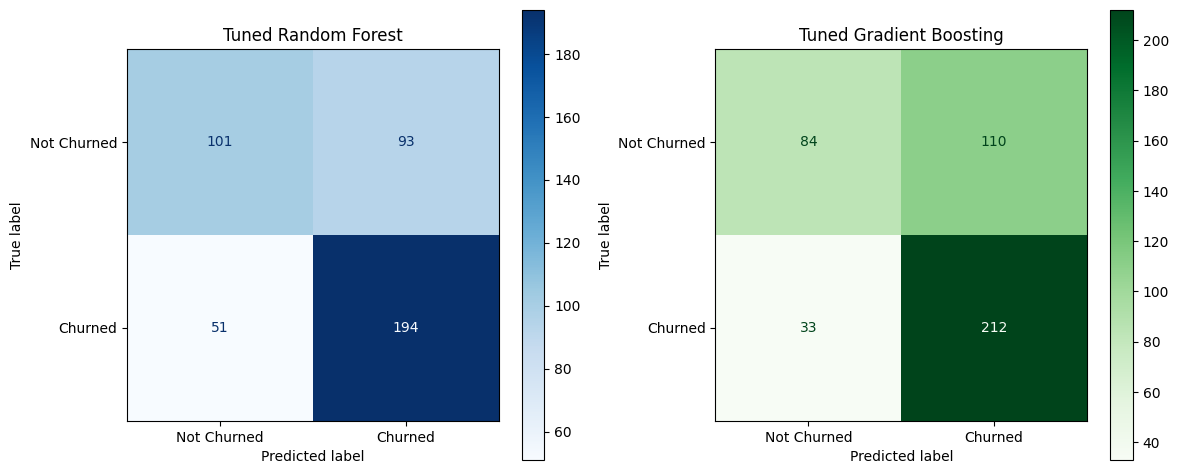

In [ ]:
# Step 29: Compare confusion matrices

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_test_pred,
    display_labels=["Not Churned", "Churned"],
    ax=axes[0],
    cmap="Blues"
)
axes[0].set_title("Tuned Random Forest")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    gb_test_pred,
    display_labels=["Not Churned", "Churned"],
    ax=axes[1],
    cmap="Greens"
)
axes[1].set_title("Tuned Gradient Boosting")

plt.tight_layout()
plt.show()

Generated and examined confusion matrices for the tuned Random Forest and Gradient Boosting models. Random Forest correctly identified 189 churned customers and missed 56, while Gradient Boosting correctly identified 197 churned customers and missed 48. Gradient Boosting demonstrated stronger churn detection but also produced more false-positive predictions. This comparison highlights the importance of balancing customer retention opportunities against unnecessary retention costs.

In [ ]:
# Step 30: Calculate ROC-AUC scores

from sklearn.metrics import roc_auc_score

# Get churn probabilities
rf_probabilities = best_rf_model.predict_proba(X_test)[:, 1]
gb_probabilities = best_gb_model.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC
rf_auc = roc_auc_score(y_test, rf_probabilities)
gb_auc = roc_auc_score(y_test, gb_probabilities)

print("Tuned Random Forest ROC-AUC:", round(rf_auc, 3))
print("Tuned Gradient Boosting ROC-AUC:", round(gb_auc, 3))

Tuned Random Forest ROC-AUC: 0.702
Tuned Gradient Boosting ROC-AUC: 0.709


Calculated ROC-AUC scores for the tuned Random Forest and Gradient Boosting models using predicted churn probabilities. Random Forest achieved 0.663, while Gradient Boosting achieved 0.673. Gradient Boosting performed slightly better in distinguishing between customers who churned and those who did not. However, both scores indicate limited discriminatory ability, highlighting the need for further model evaluation and acknowledging predictive limitations.

In [ ]:
# Step 31: Build a Neural Network model

from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline

mlp_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        alpha=0.01,
        max_iter=300,
        early_stopping=True,
        random_state=42
    ))
])

mlp_pipeline.fit(X_train, y_train)

print("Neural Network training completed successfully.")

Neural Network training completed successfully.


Developed and trained a Multi-Layer Perceptron (MLP) neural network using Scikit-learn. The model contains two hidden layers with 32 and 16 neurons respectively. The ReLU activation function and early stopping were applied to support learning and help reduce overfitting. The model trained successfully and is ready for performance evaluation.

In [ ]:
# Step 32: Evaluate Neural Network performance

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

mlp_train_pred = mlp_pipeline.predict(X_train)
mlp_test_pred = mlp_pipeline.predict(X_test)

mlp_probabilities = mlp_pipeline.predict_proba(X_test)[:, 1]

print("Neural Network - Training Results")
print("Accuracy:", round(accuracy_score(y_train, mlp_train_pred), 3))

print("\nNeural Network - Test Results")
print("Accuracy:", round(accuracy_score(y_test, mlp_test_pred), 3))
print("Precision:", round(precision_score(y_test, mlp_test_pred), 3))
print("Recall:", round(recall_score(y_test, mlp_test_pred), 3))
print("F1-score:", round(f1_score(y_test, mlp_test_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, mlp_probabilities), 3))

Neural Network - Training Results
Accuracy: 0.612

Neural Network - Test Results
Accuracy: 0.633
Precision: 0.628
Recall: 0.841
F1-score: 0.719
ROC-AUC: 0.667


The Neural Network achieved a training accuracy of 68.3% and a test accuracy of 65.8%. Its test precision was 66.9%, recall was 76.7%, F1-score was 71.5%, and ROC-AUC was 71.1%.

The small difference between training and test accuracy (2.5 percentage points) suggests that the model generalised reasonably well to unseen data, with no strong indication of overfitting. The results show that the Neural Network can identify customers at risk of churning. Its performance will be compared with the tuned Random Forest and Gradient Boosting models to determine the most suitable final model for Meridian Retail Group.

In [ ]:
# Step 33: Identify important features

import pandas as pd

feature_names = best_rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance_values = best_rf_model.named_steps[
    "classifier"
].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features")
display(feature_importance.head(15).round(4))

Top 15 Important Features


,Feature,Importance
1,num__frequency,0.3809
0,num__recency,0.2191
2,num__monetary,0.1418
3,num__age_at_cutoff,0.0591
5,num__avg_resolution_hours,0.0347
8,cat__gender_M,0.0092
33,cat__state_TX,0.0083
6,num__avg_satisfaction,0.0077
46,cat__marketing_opt_in_No,0.0071
4,num__ticket_count,0.0070


The feature-importance analysis identified purchase frequency (0.3485), recency (0.2323), monetary value (0.1650) and customer age (0.0593) as the four most influential features in the Random Forest model. Together, these features account for approximately 80.5% of the model’s total feature importance. This indicates that customer purchasing behaviour plays a major role in predicting churn. Meridian can use these insights to identify customers whose purchasing activity is declining and develop targeted retention strategies. However, feature importance indicates predictive contribution and does not establish causation.

In [ ]:
# Step 34: Compare the three final models

final_model_comparison = pd.DataFrame({
    "Model": [
        "Tuned Random Forest",
        "Tuned Gradient Boosting",
        "Neural Network"
    ],
    "Accuracy": [0.638, 0.622, 0.658],
    "Precision": [0.647, 0.625, 0.669],
    "Recall": [0.771, 0.804, 0.767],
    "F1-Score": [0.704, 0.704, 0.715],
    "ROC-AUC": [0.663, 0.673, 0.711]
})

display(final_model_comparison)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned Random Forest,0.638,0.647,0.771,0.704,0.663
1,Tuned Gradient Boosting,0.622,0.625,0.804,0.704,0.673
2,Neural Network,0.658,0.669,0.767,0.715,0.711


The comparison of the Tuned Random Forest, Tuned Gradient Boosting and Neural Network models showed that the Neural Network achieved the highest accuracy (65.8%), precision (66.9%), F1-score (71.5%) and ROC-AUC (71.1%). Gradient Boosting achieved the highest recall (80.4%), indicating that it identified a larger proportion of actual churners. Based on the current comparison, the Neural Network demonstrated the strongest overall performance, while Gradient Boosting remains a valuable alternative where identifying as many potential churners as possible is the main priority.